# RevenueRescue AI — LightGBM + Transformer Encoder Hybrid

Trains and evaluates, on the output of `RevenueRescue_AI_Data_Preprocessing.ipynb`:

| Model | Input |
| --- | --- |
| Prior baseline | training positive rate |
| Rule baseline | training recovery rate per `event_type × failure_reason` |
| LightGBM | event fields + point-in-time customer-history features (native categoricals) |
| Transformer Encoder | the customer's event sequence up to and including the prediction event (categorical embeddings, scaled numerics, time-delta, positional embedding, padding mask) |
| Hybrid | `w·P_lgbm + (1−w)·P_transformer`, `w` chosen on **validation** log loss |

**Protocol.** The primary split is the chronological `chrono_split` (train < validation < test in time).
Early stopping, the fusion weight and the decision threshold use validation data only; the test split is
scored once at the end. Sequences contain only *input* fields of the same or earlier events — never labels.

> Synthetic data. Metrics below are predictive metrics on a synthetic label, not recovered revenue.
> Model output is evidence for strategy selection only; the policy engine authorizes actions and the
> recovery verifier confirms payments.

## 1. Setup

In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import torch
from torch import nn
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, precision_score, recall_score, roc_auc_score)

SEED = 42
SPLIT_COL = os.environ.get("RR_SPLIT_COL", "chrono_split")   # "supplied_split" for the random split
MAX_LEN = 8                                                  # max events per customer in this dataset
EPOCHS, PATIENCE, BATCH, LR = 25, 4, 256, 1e-3


def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


seed_everything(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def find_root() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "preprocessed" / "events_clean.parquet").exists():
            return base
    raise FileNotFoundError("Run RevenueRescue_AI_Data_Preprocessing.ipynb first.")


ROOT = find_root()
PRE = ROOT / "data" / "preprocessed"
ART = ROOT / "models" / "artifacts"
ART.mkdir(parents=True, exist_ok=True)
print(f"python {platform.python_version()} | lightgbm {lgb.__version__} | torch {torch.__version__} | device {DEVICE}")
print("split column:", SPLIT_COL)

python 3.11.9 | lightgbm 4.5.0 | torch 2.5.1+cpu | device cpu
split column: chrono_split


## 2. Load preprocessed data

In [2]:
spec = json.loads((PRE / "feature_spec.json").read_text())
TARGET, CAT, NUM = spec["target"], spec["categorical"], spec["numeric"]
events = (pd.read_parquet(PRE / "events_clean.parquet")
          .sort_values(spec["sequence_order"]).reset_index(drop=True))
for c in CAT:
    events[c] = events[c].astype(str)
split = events[SPLIT_COL].to_numpy()
idx = {s: np.flatnonzero(split == s) for s in ("train", "validation", "test")}
y = events[TARGET].to_numpy().astype(int)
display(pd.DataFrame({s: {"rows": len(i), "positive_rate": round(y[i].mean(), 4)} for s, i in idx.items()}).T)
print("feature version:", spec["feature_version"], "| categorical:", CAT, "| numeric:", len(NUM))

,rows,positive_rate
train,70000.0,0.6190
validation,15000.0,0.6232
test,15000.0,0.6207


feature version: rr-features.v2 | categorical: ['event_type', 'failure_reason', 'payment_method', 'device_type', 'country'] | numeric: 12


## 3. Evaluation helpers

In [3]:
def choose_threshold(y_true, p):
    # Youden's J (TPR - FPR) on validation data. F1 is not used: with a 62% positive rate it is maximised by
    # predicting (almost) everything positive, which even the constant prior baseline achieves.
    if np.unique(p).size == 1:
        return 0.5
    grid = np.linspace(0.05, 0.95, 91)
    pos, neg = y_true == 1, y_true == 0
    j = [((p[pos] >= t).mean() - (p[neg] >= t).mean()) for t in grid]
    return float(grid[int(np.argmax(j))])


def evaluate(name, y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    two_classes = len(np.unique(y_true)) == 2
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"model": name, "threshold": round(threshold, 3),
            "roc_auc": roc_auc_score(y_true, p) if two_classes else np.nan,
            "pr_auc": average_precision_score(y_true, p) if two_classes else np.nan,
            "log_loss": log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]),
            "brier": brier_score_loss(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def bootstrap_auc_ci(y_true, p, n=300, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        s = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[s])) == 2:
            vals.append(roc_auc_score(y_true[s], p[s]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


preds = {}   # model name -> {"validation": array, "test": array}

## 4. Baselines

In [4]:
tr = events.iloc[idx["train"]]
prior = float(y[idx["train"]].mean())
preds["Prior baseline"] = {s: np.full(len(idx[s]), prior) for s in ("validation", "test")}

# Rule baseline: smoothed train recovery rate per (event_type, failure_reason).
K = 20
grp = tr.groupby(["event_type", "failure_reason"])[TARGET].agg(["sum", "count"])
rate = ((grp["sum"] + K * prior) / (grp["count"] + K)).rename("rule_p")
rule_all = events[["event_type", "failure_reason"]].merge(
    rate.reset_index(), on=["event_type", "failure_reason"], how="left")["rule_p"].fillna(prior).to_numpy()
preds["Rule baseline"] = {s: rule_all[idx[s]] for s in ("validation", "test")}
display(rate.unstack().round(3))

failure_reason,AUTH_FAILURE,BANK_DECLINE,CHECKOUT_ABANDONED,EXPIRED_METHOD,GATEWAY_TEMPORARY,INSUFFICIENT_FUNDS,MANDATE_FAILURE,UNKNOWN
event_type,,,,,,,,
CHECKOUT_ABANDONED,NaN,NaN,0.542,NaN,NaN,NaN,NaN,NaN
FAILED_PAYMENT,0.544,0.543,NaN,0.538,0.901,0.686,0.536,0.167
FAILED_SUBSCRIPTION,0.543,0.549,NaN,0.542,0.895,0.687,0.518,0.221


## 5. LightGBM

Native categorical handling with categories fixed from the training split. Early stopping on validation
log loss. A second model without the point-in-time history features is trained as an ablation.

In [5]:
def lgb_frame(cols):
    X = events[cols].copy()
    for c in CAT:
        if c in X:
            X[c] = pd.Categorical(X[c], categories=sorted(tr[c].unique()))
    return X


LGB_PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_child_samples=50,
                  subsample=0.85, subsample_freq=1, colsample_bytree=0.85, reg_lambda=1.0,
                  n_estimators=3000, random_state=SEED, n_jobs=-1, verbosity=-1)


def train_lgb(cols):
    X = lgb_frame(cols)
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    t0 = time.perf_counter()
    model.fit(X.iloc[idx["train"]], y[idx["train"]],
              eval_set=[(X.iloc[idx["validation"]], y[idx["validation"]])], eval_metric="binary_logloss",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    secs = time.perf_counter() - t0
    out = {s: model.predict_proba(X.iloc[idx[s]])[:, 1] for s in ("validation", "test")}
    return model, X, out, secs


LGB_COLS = CAT + NUM
lgbm, X_lgb, preds["LightGBM"], lgb_secs = train_lgb(LGB_COLS)
print(f"LightGBM: best_iteration={lgbm.best_iteration_} train_seconds={lgb_secs:.1f}")

NO_HIST = [c for c in LGB_COLS if c not in spec["history_features"]]
_, _, preds["LightGBM (no history features)"], _ = train_lgb(NO_HIST)

importance = (pd.DataFrame({"feature": LGB_COLS, "gain": lgbm.booster_.feature_importance("gain")})
              .sort_values("gain", ascending=False))
importance["gain_share"] = importance["gain"] / importance["gain"].sum()
display(importance.head(15))

LightGBM: best_iteration=137 train_seconds=2.7


,feature,gain,gain_share
1,failure_reason,81739.820971,0.690622
5,amount_paise,20491.991804,0.173137
10,cust_prior_amount_mean,3379.548653,0.028554
16,hours_since_prev_event,3070.313528,0.025941
7,event_hour_utc,2409.275254,0.020356
0,event_type,1501.887064,0.012689
8,event_dayofweek_utc,1150.092470,0.009717
6,retry_count,908.411092,0.007675
3,device_type,777.684631,0.006571
4,country,759.565647,0.006418


## 6. Transformer sequence tensors

Each prediction event becomes a right-aligned sequence of up to `MAX_LEN` tokens: the customer's earlier
events (from any split — they precede the prediction time) followed by the prediction event itself.
Token = categorical ids (0 = padding, 1 = unseen in train) + scaled numerics + `log1p(hours before the
prediction event)`. Vocabularies and scalers are fitted on training rows only.

In [6]:
TOKEN_NUM = ["amount_paise", "retry_count", "event_hour_utc", "event_dayofweek_utc"]
vocab = {c: {v: i + 2 for i, v in enumerate(sorted(tr[c].unique()))} for c in CAT}
cat_ids = np.stack([events[c].map(vocab[c]).fillna(1).astype(np.int64).to_numpy() for c in CAT], axis=1)

num_raw = events[TOKEN_NUM].astype("float64").to_numpy()
num_raw[:, 0] = np.log1p(num_raw[:, 0])
mu, sd = num_raw[idx["train"]].mean(0), num_raw[idx["train"]].std(0) + 1e-6
num_tok = ((num_raw - mu) / sd).astype(np.float32)

ts_hours = events["occurred_at"].astype("int64").to_numpy() / 3.6e12
pos_in_cust = events.groupby("customer_id", sort=False).cumcount().to_numpy()
N = len(events)
S_cat = np.zeros((N, MAX_LEN, len(CAT)), dtype=np.int64)
S_num = np.zeros((N, MAX_LEN, len(TOKEN_NUM) + 1), dtype=np.float32)
S_mask = np.zeros((N, MAX_LEN), dtype=bool)          # True = real token
rows = np.arange(N)
for lag in range(MAX_LEN):                            # lag 0 = prediction event (last slot)
    ok = pos_in_cust >= lag
    src, slot = rows[ok] - lag, MAX_LEN - 1 - lag
    S_cat[ok, slot] = cat_ids[src]
    S_num[ok, slot, :-1] = num_tok[src]
    S_num[ok, slot, -1] = np.log1p(ts_hours[rows[ok]] - ts_hours[src])
    S_mask[ok, slot] = True

# Point-in-time check: every token is the same customer and not later than the prediction event.
assert S_mask[:, -1].all()
assert (S_num[..., -1][S_mask] >= 0).all()
print("sequence tensor:", S_cat.shape, S_num.shape, "| mean real tokens:", S_mask.sum(1).mean().round(3))

sequence tensor: (100000, 8, 5) (100000, 8, 5) | mean real tokens: 1.502


## 7. Transformer Encoder

epoch 01 train=0.6269 val=0.6159


epoch 02 train=0.6183 val=0.6148


epoch 03 train=0.6179 val=0.6144


epoch 04 train=0.6172 val=0.6140


epoch 05 train=0.6165 val=0.6154


epoch 06 train=0.6161 val=0.6143


epoch 07 train=0.6155 val=0.6156


epoch 08 train=0.6150 val=0.6150
early stopping


best val log loss 0.6140 | train seconds 250.8


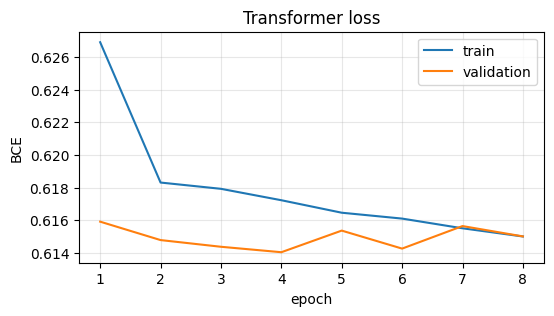

In [7]:
class RecoveryTransformer(nn.Module):
    def __init__(self, vocab_sizes, n_num, d_model=64, nhead=4, layers=2, dropout=0.1, max_len=MAX_LEN):
        super().__init__()
        self.cat_emb = nn.ModuleList([nn.Embedding(v, d_model, padding_idx=0) for v in vocab_sizes])
        self.num_proj = nn.Linear(n_num, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=4 * d_model, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Linear(2 * d_model, d_model), nn.GELU(), nn.Dropout(dropout),
                                  nn.Linear(d_model, 1))

    def forward(self, cat, num, mask):
        h = self.num_proj(num) + sum(e(cat[..., i]) for i, e in enumerate(self.cat_emb))
        h = h + self.pos(torch.arange(cat.shape[1], device=cat.device))
        h = self.norm(self.encoder(h, src_key_padding_mask=~mask))
        w = mask.unsqueeze(-1).float()
        pooled = (h * w).sum(1) / w.sum(1).clamp(min=1.0)
        return self.head(torch.cat([pooled, h[:, -1]], dim=-1)).squeeze(-1)   # mean + prediction token


def tensors(rows_):
    return (torch.from_numpy(S_cat[rows_]), torch.from_numpy(S_num[rows_]),
            torch.from_numpy(S_mask[rows_]), torch.from_numpy(y[rows_].astype(np.float32)))


@torch.no_grad()
def predict_tf(model, rows_, bs=2048):
    model.eval()
    c, n, m, _ = tensors(rows_)
    out = [torch.sigmoid(model(c[i:i + bs].to(DEVICE), n[i:i + bs].to(DEVICE), m[i:i + bs].to(DEVICE))).cpu()
           for i in range(0, len(rows_), bs)]
    return torch.cat(out).numpy()


seed_everything(SEED)
TF_CONFIG = dict(vocab_sizes=[len(vocab[c]) + 2 for c in CAT], n_num=S_num.shape[-1], d_model=64, nhead=4,
                 layers=2, dropout=0.1, max_len=MAX_LEN)
model = RecoveryTransformer(**TF_CONFIG).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()
tr_c, tr_n, tr_m, tr_y = tensors(idx["train"])
va_c, va_n, va_m, va_y = tensors(idx["validation"])
gen = torch.Generator().manual_seed(SEED)

history, best, best_state, wait = [], float("inf"), None, 0
t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train(); total = 0.0
    perm = torch.randperm(len(tr_y), generator=gen)
    for i in range(0, len(perm), BATCH):
        b = perm[i:i + BATCH]
        opt.zero_grad()
        loss = loss_fn(model(tr_c[b].to(DEVICE), tr_n[b].to(DEVICE), tr_m[b].to(DEVICE)), tr_y[b].to(DEVICE))
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        total += loss.item() * len(b)
    va_p = predict_tf(model, idx["validation"])
    va_loss = log_loss(y[idx["validation"]], np.clip(va_p, 1e-6, 1 - 1e-6))
    history.append({"epoch": epoch, "train_loss": total / len(perm), "val_loss": va_loss})
    print(f"epoch {epoch:02d} train={total / len(perm):.4f} val={va_loss:.4f}")
    if va_loss < best - 1e-4:
        best, wait = va_loss, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            print("early stopping"); break
tf_secs = time.perf_counter() - t0
model.load_state_dict(best_state)
preds["Transformer"] = {s: predict_tf(model, idx[s]) for s in ("validation", "test")}
print(f"best val log loss {best:.4f} | train seconds {tf_secs:.1f}")

h = pd.DataFrame(history)
plt.figure(figsize=(6, 3)); plt.plot(h.epoch, h.train_loss, label="train"); plt.plot(h.epoch, h.val_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("BCE"); plt.legend(); plt.grid(alpha=.3); plt.title("Transformer loss"); plt.show()

## 8. Hybrid fusion (validation-selected)

In [8]:
pv_l, pv_t = preds["LightGBM"]["validation"], preds["Transformer"]["validation"]
yv = y[idx["validation"]]
fusion = pd.DataFrame([{"w_lightgbm": w, "val_log_loss": log_loss(yv, np.clip(w * pv_l + (1 - w) * pv_t, 1e-6, 1 - 1e-6)),
                        "val_roc_auc": roc_auc_score(yv, w * pv_l + (1 - w) * pv_t)}
                       for w in np.round(np.linspace(0, 1, 21), 2)])
W = float(fusion.loc[fusion.val_log_loss.idxmin(), "w_lightgbm"])
preds["Hybrid"] = {s: W * preds["LightGBM"][s] + (1 - W) * preds["Transformer"][s] for s in ("validation", "test")}
print(f"selected weights: LightGBM={W:.2f} Transformer={1 - W:.2f}")
display(fusion.sort_values("val_log_loss").head(5))

selected weights: LightGBM=0.80 Transformer=0.20


,w_lightgbm,val_log_loss,val_roc_auc
16,0.80,0.612057,0.658326
17,0.85,0.612064,0.658444
15,0.75,0.612065,0.658186
18,0.90,0.612088,0.658517
14,0.70,0.612089,0.658049


## 9. Held-out test evaluation

Thresholds maximise Youden's J (TPR − FPR) on validation and are frozen before scoring the test split. The test split is used
only here. 95% CIs for ROC-AUC are from 300 bootstrap resamples of the test split.

In [9]:
yt = y[idx["test"]]
rows_out = []
for name, p in preds.items():
    thr = choose_threshold(yv, p["validation"])
    r = evaluate(name, yt, p["test"], thr)
    if np.unique(p["test"]).size > 1:
        r["roc_auc_ci95"] = "[{:.4f}, {:.4f}]".format(*bootstrap_auc_ci(yt, p["test"]))
    rows_out.append(r)
test_results = pd.DataFrame(rows_out).set_index("model")
display(test_results.round(4))

,threshold,roc_auc,pr_auc,log_loss,brier,precision,recall,f1,tn,fp,fn,tp,roc_auc_ci95
model,,,,,,,,,,,,,
Prior baseline,0.50,0.5000,0.6207,0.6637,0.2354,0.6207,1.0000,0.7659,0,5690,0,9310,NaN
Rule baseline,0.55,0.6383,0.7410,0.6203,0.2171,0.7587,0.4850,0.5917,4254,1436,4795,4515,"[0.6299, 0.6466]"
LightGBM,0.63,0.6640,0.7773,0.6130,0.2145,0.7608,0.4697,0.5808,4315,1375,4937,4373,"[0.6551, 0.6719]"
LightGBM (no history features),0.62,0.6643,0.7776,0.6128,0.2145,0.7657,0.4649,0.5785,4366,1324,4982,4328,"[0.6560, 0.6717]"
Transformer,0.62,0.6628,0.7769,0.6139,0.2149,0.7739,0.4402,0.5612,4493,1197,5212,4098,"[0.6542, 0.6708]"
Hybrid,0.63,0.6648,0.7781,0.6127,0.2144,0.7723,0.4533,0.5713,4446,1244,5090,4220,"[0.6558, 0.6727]"


### Segment performance and calibration (hybrid)

,rows,positive_rate,roc_auc
event_type,,,
CHECKOUT_ABANDONED,2936.0,0.5559,0.5532
FAILED_PAYMENT,8298.0,0.6374,0.6904
FAILED_SUBSCRIPTION,3766.0,0.6344,0.6740


,rows,mean_pred,observed
bin,,,
"(0.1, 0.2]",203,0.180,0.143
"(0.2, 0.3]",61,0.220,0.295
"(0.3, 0.4]",12,0.391,0.333
"(0.4, 0.5]",1965,0.479,0.468
"(0.5, 0.6]",5636,0.546,0.556
"(0.6, 0.7]",4048,0.646,0.646
"(0.7, 0.8]",1366,0.754,0.755
"(0.8, 0.9]",827,0.854,0.874
"(0.9, 1.0]",882,0.943,0.951


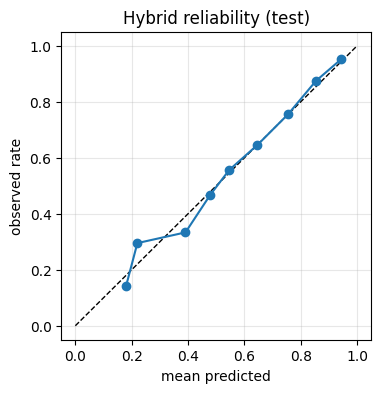

In [10]:
te = events.iloc[idx["test"]].assign(p=preds["Hybrid"]["test"])
seg = (te.groupby("event_type")
       .apply(lambda d: pd.Series({"rows": len(d), "positive_rate": d[TARGET].mean(),
                                   "roc_auc": roc_auc_score(d[TARGET], d.p)}), include_groups=False))
display(seg.round(4))

te["bin"] = pd.cut(te.p, np.linspace(0, 1, 11), include_lowest=True)
calib = te.groupby("bin", observed=True).agg(rows=("p", "size"), mean_pred=("p", "mean"), observed=(TARGET, "mean"))
display(calib.round(3))
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.plot(calib.mean_pred, calib.observed, "o-"); plt.xlabel("mean predicted"); plt.ylabel("observed rate")
plt.title("Hybrid reliability (test)"); plt.grid(alpha=.3); plt.show()

## 10. Inference latency and model size

In [11]:
one = idx["test"][:1]
def time_it(fn, reps=200):
    fn(); t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1000

lat = {
    "lightgbm_single_ms": time_it(lambda: lgbm.predict_proba(X_lgb.iloc[one])),
    "transformer_single_ms": time_it(lambda: predict_tf(model, one)),
    "lightgbm_batch_1000_ms": time_it(lambda: lgbm.predict_proba(X_lgb.iloc[idx["test"][:1000]]), 20),
    "transformer_batch_1000_ms": time_it(lambda: predict_tf(model, idx["test"][:1000]), 20),
}
size = {"transformer_parameters": int(sum(p.numel() for p in model.parameters())),
        "lightgbm_trees": int(lgbm.booster_.num_trees())}
print(json.dumps({**{k: round(v, 3) for k, v in lat.items()}, **size}, indent=2))

{
  "lightgbm_single_ms": 11.405,
  "transformer_single_ms": 5.626,
  "lightgbm_batch_1000_ms": 19.92,
  "transformer_batch_1000_ms": 75.105,
  "transformer_parameters": 111425,
  "lightgbm_trees": 137
}


## 11. Persist artifacts and verify reload

In [12]:
lgbm.booster_.save_model(str(ART / "lightgbm.txt"))
torch.save({"state_dict": model.state_dict(), "config": TF_CONFIG, "categorical": CAT, "token_numeric": TOKEN_NUM,
            "vocab": vocab, "num_mean": mu.tolist(), "num_std": sd.tolist()}, ART / "transformer.pt")
metadata = {
    "model_version": "rr-hybrid.v1",
    "feature_version": spec["feature_version"],
    "trained_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "split_column": SPLIT_COL,
    "seed": SEED,
    "lightgbm": {"features": LGB_COLS, "categories": {c: sorted(tr[c].unique()) for c in CAT},
                 "best_iteration": int(lgbm.best_iteration_), "train_seconds": round(lgb_secs, 2)},
    "transformer": {"max_len": MAX_LEN, "epochs_run": len(history), "best_val_log_loss": round(best, 5),
                    "train_seconds": round(tf_secs, 2), **size},
    "fusion": {"w_lightgbm": W, "w_transformer": 1 - W, "selected_on": "validation log loss"},
    "decision_threshold": choose_threshold(yv, preds["Hybrid"]["validation"]),
    "test_metrics": json.loads(test_results.reset_index().to_json(orient="records")),
    "latency_ms": {k: round(v, 3) for k, v in lat.items()},
    "data": {"synthetic": True, "rows": {s: int(len(i)) for s, i in idx.items()}},
    "interpretation": "Predictive metrics on a synthetic label. Not recovered revenue; not an authorization.",
}
(ART / "hybrid_metadata.json").write_text(json.dumps(metadata, indent=2, default=str))
pd.DataFrame({"event_id": events.event_id.iloc[idx["test"]].to_numpy(), "y": yt,
              **{k.lower().replace(" ", "_").replace("(", "").replace(")", ""): v["test"] for k, v in preds.items()}}
             ).to_parquet(ART / "test_predictions.parquet", index=False)

# Reload from disk and confirm identical predictions.
booster = lgb.Booster(model_file=str(ART / "lightgbm.txt"))
assert np.allclose(booster.predict(X_lgb.iloc[idx["test"]]), preds["LightGBM"]["test"], atol=1e-9)
ckpt = torch.load(ART / "transformer.pt", weights_only=False)
reloaded = RecoveryTransformer(**ckpt["config"]).to(DEVICE)
reloaded.load_state_dict(ckpt["state_dict"])
assert np.allclose(predict_tf(reloaded, idx["test"]), preds["Transformer"]["test"], atol=1e-6)
print("artifacts reloaded and verified:", sorted(p.name for p in ART.iterdir()))

artifacts reloaded and verified: ['hybrid_metadata.json', 'lightgbm.txt', 'test_predictions.parquet', 'transformer.pt']


## 12. Interpretation and limitations

- Results are on the synthetic `recovered` label; read them against the rule baseline. If the hybrid does not
  beat the baseline by more than its bootstrap CI, the models add no demonstrated value on this dataset.
- `customer_profiles.csv` is not joinable (0% key match) and `customer_history_features.csv` is a
  whole-period snapshot that leaks the label (see the preprocessing leakage audit); neither is used.
- Sequences are short (≈1.6 events per customer), which limits what the Transformer can learn.
- The fusion weight and threshold are validation-selected; probability calibration is reported, not corrected.
- Local single-node pandas/PyTorch; this notebook is not a Spark/HDFS pipeline.